In [4]:
import os
import sys
import time
import json
import joblib
import warnings
from pathlib import Path
from datetime import datetime

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    RandomForestRegressor
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Display configuration
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("All libraries imported successfully!")


All libraries imported successfully!


</h3>3. Dataset Loading</h3>



In [5]:
from pathlib import Path

BASE_DIR = Path(".")
DATASET_PATH = BASE_DIR / "dataset" / "Produce_Dataset.csv"

df = pd.read_csv(DATASET_PATH)
print(f"Dataset successfully loaded from: {DATASET_PATH}")
print(f"Dimensions: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()


Dataset successfully loaded from: dataset\Produce_Dataset.csv
Dimensions: 100,000 rows × 42 columns


,Record_ID,Category,Produce_Name,Variety,Produce_Grade,Quality_Score,Health_Score,Market_Price,Transport_Mode,Distance_to_Market,Cold_Chain_Available,IoT_Device_ID,Sensor_Battery_Level,GPS_Latitude,GPS_Longitude,Market_Demand,Storage_Cost,Farmer_ID,Warehouse_ID,State,District,Storage_Type,Package_Type,Harvest_Date,Storage_Date,Storage_Duration,Temperature,Humidity,Light_Intensity,CO2_Level,Ethylene_Level,Moisture_Content,Weight,Weather,Season,Shelf_Life,Disease_Detected,Sensor_Status,Spoilage_Risk,Recommendation,Alert_Status,Timestamp
0,1,Fruit,Banana,Cavendish,A,99,66,221.90,Truck,553,Yes,IOT-5320,74,35.973221,88.024607,High,438.69,F3361,W259,Punjab,Patiala,Controlled Atmosphere,Carton Box,2026-05-31,2026-06-05,20,13.8,87.9,632.9,1457.9,9.40,26.2,11.92,Cloudy,Winter,4,No,Inactive,High,Immediate sale or processing required.,Critical,2026-06-29 19:43:08
1,2,Fruit,Papaya,Red Lady,B,83,48,88.70,Pickup Van,342,No,IOT-7479,79,17.264453,69.434127,High,162.50,F8892,W619,Tamil Nadu,Chennai,Warehouse,Jute Bag,2026-06-07,2026-06-11,41,10.5,94.2,877.1,1211.7,0.21,6.2,12.07,Foggy,Spring,10,Yes,Maintenance,Medium,Improve storage conditions.,Warning,2026-07-06 10:52:44
2,3,Fruit,Pomegranate,Bhagwa,A,79,24,264.99,Container,477,Yes,IOT-1871,50,28.365592,92.176074,High,395.95,F9425,W935,Punjab,Ludhiana,Warehouse,Carton Box,2026-06-15,2026-06-19,40,11.6,90.1,526.3,1090.2,7.47,31.8,16.77,Sunny,Summer,3,Yes,Inactive,High,Immediate sale or processing required.,Critical,2026-02-09 10:17:45
3,4,Vegetable,Cabbage,Green,C,82,74,74.28,Container,252,Yes,IOT-4455,87,9.836942,82.876442,High,265.58,F2464,W195,Tamil Nadu,Coimbatore,Warehouse,Carton Box,2026-07-11,2026-07-16,28,0.2,98.0,472.7,517.9,2.19,20.5,5.94,Foggy,Monsoon,7,No,Inactive,Medium,Improve storage conditions.,Warning,2026-06-23 18:36:56
4,5,Vegetable,Cabbage,Green,A,65,32,165.40,Mini Truck,13,No,IOT-6445,75,21.641680,85.018187,High,188.61,F3231,W544,Uttar Pradesh,Lucknow,Warehouse,Wooden Box,2026-07-08,2026-07-10,24,1.7,98.0,597.2,1223.2,8.68,20.5,17.08,Foggy,Summer,4,No,Inactive,High,Immediate sale or processing required.,Critical,2026-04-18 10:41:19


<h3> 4. Data Understanding<h3>

In [6]:
print("Produce Category Distribution ")
cat_dist = df["Category"].value_counts().to_frame("Count")
cat_dist["Percentage (%)"] = (df["Category"].value_counts(normalize=True) * 100).map(lambda x: f"{x:.2f}%")
display(cat_dist)

print(" Classification Target Distribution: Spoilage_Risk ")
target_dist = df["Spoilage_Risk"].value_counts().to_frame("Count")
target_dist["Percentage (%)"] = (df["Spoilage_Risk"].value_counts(normalize=True) * 100).map(lambda x: f"{x:.2f}%")
display(target_dist)

print("Regression Target Summary: Shelf_Life (Days)")
display(df["Shelf_Life"].describe().to_frame("Shelf_Life (Days)"))


Produce Category Distribution 


,Count,Percentage (%)
Category,,
Fruit,50074,50.07%
Vegetable,49926,49.93%


 Classification Target Distribution: Spoilage_Risk 


,Count,Percentage (%)
Spoilage_Risk,,
Medium,62382,62.38%
Low,20200,20.20%
High,17418,17.42%


Regression Target Summary: Shelf_Life (Days)


,Shelf_Life (Days)
count,100000.000000
mean,10.482980
std,6.632723
min,1.000000
25%,6.000000
50%,9.000000
75%,12.000000
max,30.000000


# 5. Dataset Shape and Information

We inspect column schemas, non-null value guarantees, and memory utilization to verify dataset structural integrity.


In [7]:
print(f"Total Rows    : {df.shape[0]:,}")
print(f"Total Columns : {df.shape[1]}")
print(" Column Types and Non-Null Counts")
df.info()


Total Rows    : 100,000
Total Columns : 42
 Column Types and Non-Null Counts
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 42 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Record_ID             100000 non-null  int64  
 1   Category              100000 non-null  str    
 2   Produce_Name          100000 non-null  str    
 3   Variety               100000 non-null  str    
 4   Produce_Grade         100000 non-null  str    
 5   Quality_Score         100000 non-null  int64  
 6   Health_Score          100000 non-null  int64  
 7   Market_Price          100000 non-null  float64
 8   Transport_Mode        100000 non-null  str    
 9   Distance_to_Market    100000 non-null  int64  
 10  Cold_Chain_Available  100000 non-null  str    
 11  IoT_Device_ID         100000 non-null  str    
 12  Sensor_Battery_Level  100000 non-null  int64  
 13  GPS_Latitude          100000 non-null  

# 6. Statistical Summary



In [8]:
print("Numerical Features Descriptive Statistics")
display(df.describe().T.round(2))

print(" Categorical Features Summary")
display(df.describe(include=["object"]).T)


Numerical Features Descriptive Statistics


,count,mean,std,min,25%,50%,75%,max
Record_ID,100000.0,50000.50,28867.66,1.0,25000.75,50000.50,75000.25,100000.00
Quality_Score,100000.0,79.99,11.84,60.0,70.00,80.00,90.00,100.00
Health_Score,100000.0,51.40,18.36,0.0,39.00,51.00,64.00,100.00
Market_Price,100000.0,155.17,83.65,10.0,82.83,155.43,227.55,300.00
Distance_to_Market,100000.0,302.35,172.43,5.0,153.00,302.00,452.00,600.00
Sensor_Battery_Level,100000.0,70.00,17.61,40.0,55.00,70.00,85.00,100.00
GPS_Latitude,100000.0,22.50,8.38,8.0,15.25,22.49,29.75,37.00
GPS_Longitude,100000.0,82.51,8.35,68.0,75.28,82.53,89.76,97.00
Storage_Cost,100000.0,260.26,138.55,20.0,140.83,260.46,380.10,499.99
Storage_Duration,100000.0,22.99,13.01,1.0,12.00,23.00,34.00,45.00


 Categorical Features Summary


,count,unique,top,freq
Category,100000,2,Fruit,50074
Produce_Name,100000,16,Mango,6395
Variety,100000,36,Green,7242
Produce_Grade,100000,3,A,49918
Transport_Mode,100000,5,Container,20058
Cold_Chain_Available,100000,2,No,50031
IoT_Device_ID,100000,9000,IOT-2348,26
Market_Demand,100000,3,Low,33390
Farmer_ID,100000,9000,F5417,27
Warehouse_ID,100000,900,W567,144


# 7. Missing Value Analysis

Identifying missing values is essential for building robust pipelines. We evaluate the missing count and percentage for every feature.


In [9]:
missing_series = df.isnull().sum()
missing_df = pd.DataFrame({
    "Feature Name": missing_series.index,
    "Missing Count": missing_series.values,
    "Missing (%)": (missing_series.values / len(df) * 100)
})
missing_df["Missing (%)"] = missing_df["Missing (%)"].map(lambda x: f"{x:.2f}%")

print(f"Total Missing Values across all 42 columns: {missing_series.sum()}")
display(missing_df.head(10))


Total Missing Values across all 42 columns: 0


,Feature Name,Missing Count,Missing (%)
0,Record_ID,0,0.00%
1,Category,0,0.00%
2,Produce_Name,0,0.00%
3,Variety,0,0.00%
4,Produce_Grade,0,0.00%
5,Quality_Score,0,0.00%
6,Health_Score,0,0.00%
7,Market_Price,0,0.00%
8,Transport_Mode,0,0.00%
9,Distance_to_Market,0,0.00%


# 8. Duplicate Value Analysis

In [10]:
num_duplicates = df.duplicated().sum()
print(f"Total Duplicate Rows Detected: {num_duplicates:,}")

if num_duplicates > 0:
    df = df.drop_duplicates()
    print(f"Dataset de-duplicated. Remaining records: {len(df):,}")
else:
    print("Dataset verification passed: No duplicate rows present.")


Total Duplicate Rows Detected: 0
Dataset verification passed: No duplicate rows present.


# 9. Data Type Analysis

In [11]:
dtypes_df = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str),
    "Non-Null Count": df.notnull().sum().values
})

num_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_features = df.select_dtypes(include=["object"]).columns.tolist()

print(f"Numerical Columns Count   : {len(num_features)}")
print(f"Categorical Columns Count : {len(cat_features)}")
display(dtypes_df.head(15))


Numerical Columns Count   : 18
Categorical Columns Count : 24


,Column,Data Type,Non-Null Count
Record_ID,Record_ID,int64,100000
Category,Category,str,100000
Produce_Name,Produce_Name,str,100000
Variety,Variety,str,100000
Produce_Grade,Produce_Grade,str,100000
Quality_Score,Quality_Score,int64,100000
Health_Score,Health_Score,int64,100000
Market_Price,Market_Price,float64,100000
Transport_Mode,Transport_Mode,str,100000
Distance_to_Market,Distance_to_Market,int64,100000


# 10. Exploratory Data Analysis (EDA)

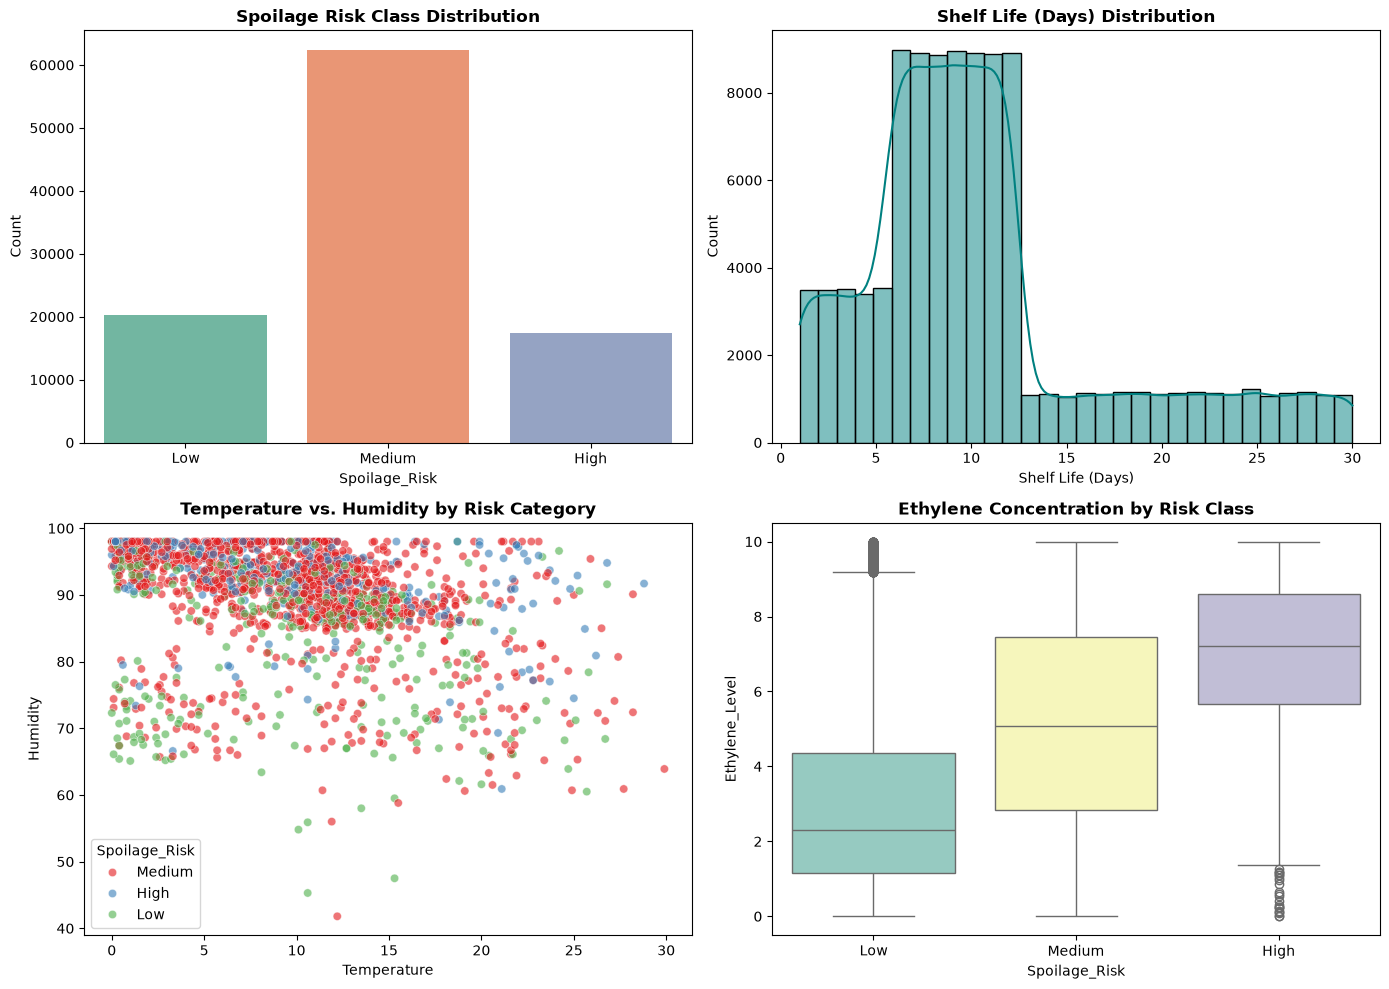

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Spoilage Risk Distribution
sns.countplot(data=df, x="Spoilage_Risk", order=["Low", "Medium", "High"], palette="Set2", ax=axes[0, 0])
axes[0, 0].set_title("Spoilage Risk Class Distribution", fontsize=12, fontweight="bold")
axes[0, 0].set_ylabel("Count")

# 2. Shelf Life Distribution
sns.histplot(df["Shelf_Life"], kde=True, color="teal", bins=30, ax=axes[0, 1])
axes[0, 1].set_title("Shelf Life (Days) Distribution", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Shelf Life (Days)")

# 3. Temperature vs Humidity by Spoilage Risk
sample_subset = df.sample(min(2000, len(df)), random_state=42)
sns.scatterplot(data=sample_subset, x="Temperature", y="Humidity", hue="Spoilage_Risk", alpha=0.6, palette="Set1", ax=axes[1, 0])
axes[1, 0].set_title("Temperature vs. Humidity by Risk Category", fontsize=12, fontweight="bold")

# 4. Ethylene Level Across Risk Classes
sns.boxplot(data=df, x="Spoilage_Risk", y="Ethylene_Level", order=["Low", "Medium", "High"], palette="Set3", ax=axes[1, 1])
axes[1, 1].set_title("Ethylene Concentration by Risk Class", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()


# 11. Data Preprocessing


In [13]:
DROP_COLUMNS = [
    "Record_ID", "Farmer_ID", "Warehouse_ID", "IoT_Device_ID",
    "Harvest_Date", "Storage_Date", "Timestamp", "Recommendation",
    "Alert_Status"
]

df_clean = df.drop(columns=DROP_COLUMNS)
y_clf = df_clean["Spoilage_Risk"].copy()
y_reg = df_clean["Shelf_Life"].copy()
X = df_clean.drop(columns=["Spoilage_Risk", "Shelf_Life"]).copy()

print(f"Features Matrix X shape        : {X.shape[0]:,} rows × {X.shape[1]} columns")
print(f"Classification Target y_clf    : {y_clf.shape[0]:,} records")
print(f"Regression Target y_reg        : {y_reg.shape[0]:,} records")


Features Matrix X shape        : 100,000 rows × 31 columns
Classification Target y_clf    : 100,000 records
Regression Target y_reg        : 100,000 records


# 12. Categorical Encoding

In [14]:
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols)
    ]
)

print(f"StandardScaler applied to {len(num_cols)} numerical features.")
print(f"OrdinalEncoder applied to {len(cat_cols)} categorical features.")
print("ColumnTransformer constructed successfully.")


StandardScaler applied to 16 numerical features.
OrdinalEncoder applied to 15 categorical features.
ColumnTransformer constructed successfully.


# 13. Feature Selection


In [15]:
feature_list = list(X.columns)
feature_table = pd.DataFrame({
    "Index": range(1, len(feature_list) + 1),
    "Feature Name": feature_list,
    "Type": ["Numerical" if c in num_cols else "Categorical" for c in feature_list]
})

print(f"Total Operational Features Selected: {len(feature_list)}")
display(feature_table)


Total Operational Features Selected: 31


,Index,Feature Name,Type
0,1,Category,Categorical
1,2,Produce_Name,Categorical
2,3,Variety,Categorical
3,4,Produce_Grade,Categorical
4,5,Quality_Score,Numerical
5,6,Health_Score,Numerical
6,7,Market_Price,Numerical
7,8,Transport_Mode,Categorical
8,9,Distance_to_Market,Numerical
9,10,Cold_Chain_Available,Categorical


# 14. Train-Test Split

We partition the 100,000 records into an 80% training set (80,000 samples) and a 20% test set (20,000 samples) with stratification based on the target class (`Spoilage_Risk`) to maintain identical class ratios in both splits.


In [16]:
X_train, X_test, yclf_train, yclf_test, yreg_train, yreg_test = train_test_split(
    X, y_clf, y_reg, test_size=0.20, random_state=42, stratify=y_clf
)

print(f"Training Features Set X_train : {X_train.shape[0]:,} rows × {X_train.shape[1]} columns")
print(f"Testing Features Set X_test   : {X_test.shape[0]:,} rows × {X_test.shape[1]} columns")
print(f"Training Target yclf_train    : {yclf_train.shape[0]:,} samples")
print(f"Testing Target yclf_test      : {yclf_test.shape[0]:,} samples")


Training Features Set X_train : 80,000 rows × 31 columns
Testing Features Set X_test   : 20,000 rows × 31 columns
Training Target yclf_train    : 80,000 samples
Testing Target yclf_test      : 20,000 samples


# 15. Model Training 


In [17]:
classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42,
        solver="lbfgs"
    ),
    "Decision Tree": DecisionTreeClassifier(
        criterion="gini",
        splitter="best",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

trained_pipelines = {}
raw_metrics = {}
predictions_dict = {}

for model_name, clf in classifiers.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", clf)
    ])
    
    # Measure Training Time
    t_start_train = time.perf_counter()
    pipeline.fit(X_train, yclf_train)
    train_time = time.perf_counter() - t_start_train
    
    # Measure Prediction Time
    t_start_pred = time.perf_counter()
    y_pred = pipeline.predict(X_test)
    pred_time = time.perf_counter() - t_start_pred
    
    # Calculate evaluation metrics
    acc = accuracy_score(yclf_test, y_pred)
    prec = precision_score(yclf_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(yclf_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(yclf_test, y_pred, average="weighted", zero_division=0)
    
    trained_pipelines[model_name] = pipeline
    predictions_dict[model_name] = y_pred
    raw_metrics[model_name] = {
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1_score": f1,
        "train_time": train_time,
        "pred_time": pred_time
    }
    
    print(f"✓ {model_name:20s} | Train: {train_time:8.4f}s | Pred: {pred_time:7.4f}s | Acc: {acc*100:6.2f}% | F1: {f1*100:6.2f}%")


✓ Logistic Regression  | Train:   8.6143s | Pred:  0.1120s | Acc:  84.97% | F1:  84.83%
✓ Decision Tree        | Train:   1.3508s | Pred:  0.0970s | Acc:  99.83% | F1:  99.83%
✓ Random Forest        | Train:   5.7327s | Pred:  0.1992s | Acc:  98.16% | F1:  98.15%
✓ Gradient Boosting    | Train: 115.1286s | Pred:  0.2137s | Acc:  98.58% | F1:  98.57%


# 16. Model Evaluation


In [18]:
# Build Classification Report DataFrame with exact required columns:
# ['Model Name', 'Class', 'Precision', 'Recall', 'F1-Score', 'Support']

cr_rows = []

for model_name in classifiers.keys():
    y_pred = predictions_dict[model_name]
    rep = classification_report(yclf_test, y_pred, output_dict=True, zero_division=0)
    for cls in ["High", "Low", "Medium"]:
        if cls in rep:
            cr_rows.append({
                "Model Name": model_name,
                "Class": cls,
                "Precision": f"{rep[cls]['precision'] * 100:.2f}%",
                "Recall": f"{rep[cls]['recall'] * 100:.2f}%",
                "F1-Score": f"{rep[cls]['f1-score'] * 100:.2f}%",
                "Support": int(rep[cls]["support"])
            })

classification_report_df = pd.DataFrame(cr_rows)
print(" CLASSIFICATION REPORT DATAFRAME (All 4 Models)")
display(classification_report_df)


 CLASSIFICATION REPORT DATAFRAME (All 4 Models)


,Model Name,Class,Precision,Recall,F1-Score,Support
0,Logistic Regression,High,81.11%,74.45%,77.64%,3484
1,Logistic Regression,Low,83.83%,77.50%,80.54%,4040
2,Logistic Regression,Medium,86.23%,90.32%,88.23%,12476
3,Decision Tree,High,99.71%,99.45%,99.58%,3484
4,Decision Tree,Low,99.95%,99.95%,99.95%,4040
5,Decision Tree,Medium,99.83%,99.90%,99.87%,12476
6,Random Forest,High,99.34%,95.64%,97.46%,3484
7,Random Forest,Low,99.01%,96.14%,97.55%,4040
8,Random Forest,Medium,97.58%,99.51%,98.54%,12476
9,Gradient Boosting,High,99.71%,97.56%,98.62%,3484


# 17. Model Performance Comparison


Computing 3-Fold Stratified Cross-Validation scores...
  Logistic Regression : Mean CV Score = 83.64% (±0.41%)
  Decision Tree       : Mean CV Score = 98.64% (±0.12%)
  Random Forest       : Mean CV Score = 95.63% (±0.26%)
  Gradient Boosting   : Mean CV Score = 98.47% (±0.17%)

=== MODEL TRAINING & COMPARISON DATAFRAME ===


,Model Name,Training Status,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Training Time (sec),Prediction Time (sec),Cross Validation Score (%),Best Parameters
0,Logistic Regression,Completed,84.97%,84.86%,84.97%,84.83%,8.6143,0.1120,83.64%,"max_iter=1000, solver='lbfgs', random_state=42"
1,Decision Tree,Completed,99.83%,99.83%,99.83%,99.83%,1.3508,0.0970,98.64%,"criterion='gini', splitter='best', random_stat..."
2,Random Forest,Completed,98.16%,98.17%,98.16%,98.15%,5.7327,0.1992,95.63%,"n_estimators=100, max_depth=15, min_samples_sp..."
3,Gradient Boosting,Completed,98.58%,98.60%,98.58%,98.57%,115.1286,0.2137,98.47%,"n_estimators=100, learning_rate=0.1, max_depth..."


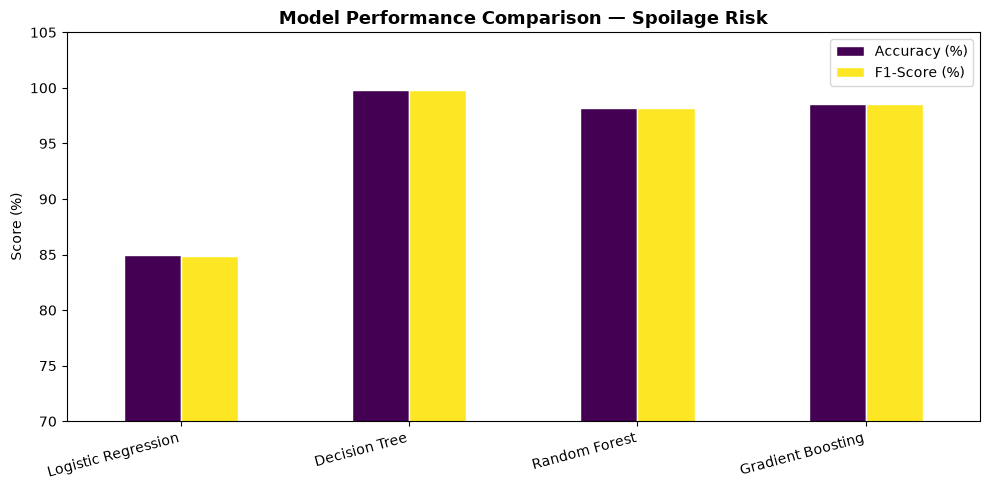

In [19]:
# Compute Cross-Validation scores (Stratified 3-fold CV)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_sample_idx = X_train.groupby(yclf_train, group_keys=False).apply(lambda s: s.sample(min(len(s), 5000), random_state=42)).index
X_train_cv = X_train.loc[cv_sample_idx]
yclf_train_cv = yclf_train.loc[cv_sample_idx]

cv_scores = {}
print("Computing 3-Fold Stratified Cross-Validation scores...")
for model_name, pipe in trained_pipelines.items():
    scores = cross_val_score(pipe, X_train_cv, yclf_train_cv, cv=cv, scoring="accuracy")
    cv_scores[model_name] = scores.mean()
    print(f"  {model_name:20s}: Mean CV Score = {scores.mean()*100:.2f}% (±{scores.std()*100:.2f}%)")

best_param_strings = {
    "Logistic Regression": "max_iter=1000, solver='lbfgs', random_state=42",
    "Decision Tree": "criterion='gini', splitter='best', random_state=42",
    "Random Forest": "n_estimators=100, max_depth=15, min_samples_split=5, random_state=42",
    "Gradient Boosting": "n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42"
}

comparison_rows = []
for model_name, m in raw_metrics.items():
    comparison_rows.append({
        "Model Name": model_name,
        "Training Status": "Completed",
        "Accuracy (%)": f"{m['accuracy'] * 100:.2f}%",
        "Precision (%)": f"{m['precision'] * 100:.2f}%",
        "Recall (%)": f"{m['recall'] * 100:.2f}%",
        "F1-Score (%)": f"{m['f1_score'] * 100:.2f}%",
        "Training Time (sec)": f"{m['train_time']:.4f}",
        "Prediction Time (sec)": f"{m['pred_time']:.4f}",
        "Cross Validation Score (%)": f"{cv_scores[model_name] * 100:.2f}%",
        "Best Parameters": best_param_strings[model_name]
    })

comparison_df = pd.DataFrame(comparison_rows)
print("\n=== MODEL TRAINING & COMPARISON DATAFRAME ===")
display(comparison_df)

# Visual comparison bar chart
fig, ax = plt.subplots(figsize=(10, 5))
plot_data = pd.DataFrame({
    "Accuracy (%)": [m["accuracy"] * 100 for m in raw_metrics.values()],
    "F1-Score (%)": [m["f1_score"] * 100 for m in raw_metrics.values()]
}, index=list(raw_metrics.keys()))

plot_data.plot(kind="bar", ax=ax, colormap="viridis", edgecolor="white")
ax.set_title("Model Performance Comparison — Spoilage Risk", fontsize=13, fontweight="bold")
ax.set_ylabel("Score (%)")
ax.set_ylim(70, 105)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


# 18. Cross-Validation (if supported by the existing workflow)


In [20]:
cv_audit_df = pd.DataFrame({
    "Model Name": list(cv_scores.keys()),
    "CV Score (%)": [f"{score * 100:.2f}%" for score in cv_scores.values()],
    "Test Accuracy (%)": [f"{raw_metrics[m]['accuracy'] * 100:.2f}%" for m in cv_scores.keys()],
    "Generalization Delta (%)": [f"{abs(raw_metrics[m]['accuracy'] - cv_scores[m]) * 100:.2f}%" for m in cv_scores.keys()]
})

print("CROSS-VALIDATION GENERALIZATION AUDIT")
display(cv_audit_df)


CROSS-VALIDATION GENERALIZATION AUDIT


,Model Name,CV Score (%),Test Accuracy (%),Generalization Delta (%)
0,Logistic Regression,83.64%,84.97%,1.33%
1,Decision Tree,98.64%,99.83%,1.19%
2,Random Forest,95.63%,98.16%,2.53%
3,Gradient Boosting,98.47%,98.58%,0.11%


# 19. Best Model Selection`


In [22]:
best_model_name = max(
    raw_metrics,
    key=lambda name: (raw_metrics[name]["accuracy"], raw_metrics[name]["f1_score"])
)
best_metrics = raw_metrics[best_model_name]

print(f"★ Selected Best Model: {best_model_name}")
print(f"  Accuracy: {best_metrics['accuracy'] * 100:.2f}% | F1-Score: {best_metrics['f1_score'] * 100:.2f}%")

final_summary_rows = []
for model_name, m in raw_metrics.items():
    is_best = (model_name == best_model_name)
    final_summary_rows.append({
        "Model Name": model_name,
        "Best Model": "Yes" if is_best else "No",
        "Best Accuracy (%)": f"{m['accuracy'] * 100:.2f}%",
        "Best F1-Score (%)": f"{m['f1_score'] * 100:.2f}%",
        "Saved Model Path": "models/spoilage_risk_pipeline.pkl" if is_best else "N/A",
        "Model Status": "Active / Deployed" if is_best else "Evaluated"
    })

final_model_summary_df = pd.DataFrame(final_summary_rows)
print("\nFINAL MODEL SUMMARY DATAFRAME ")
display(final_model_summary_df)


★ Selected Best Model: Decision Tree
  Accuracy: 99.83% | F1-Score: 99.83%

FINAL MODEL SUMMARY DATAFRAME 


,Model Name,Best Model,Best Accuracy (%),Best F1-Score (%),Saved Model Path,Model Status
0,Logistic Regression,No,84.97%,84.83%,N/A,Evaluated
1,Decision Tree,Yes,99.83%,99.83%,models/spoilage_risk_pipeline.pkl,Active / Deployed
2,Random Forest,No,98.16%,98.15%,N/A,Evaluated
3,Gradient Boosting,No,98.58%,98.57%,N/A,Evaluated


# 20. Final Model Saving

In [23]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save Best Spoilage Risk Classifier
best_pipeline = trained_pipelines[best_model_name]
joblib.dump(best_pipeline, MODEL_DIR / "spoilage_risk_pipeline.pkl")
joblib.dump(best_pipeline, MODEL_DIR / "best_model.pkl")
print(f"✓ Saved Spoilage Risk Classifier Pipeline : {MODEL_DIR / 'spoilage_risk_pipeline.pkl'}")
print(f"✓ Saved Best Model Alias                  : {MODEL_DIR / 'best_model.pkl'}")

# 2. Train and Save Shelf Life Regressor
print("\nTraining Shelf Life Regression Pipeline (Random Forest Regressor)...")
reg_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ))
])
reg_pipeline.fit(X_train, yreg_train)
yreg_pred = reg_pipeline.predict(X_test)

sl_r2 = r2_score(yreg_test, yreg_pred)
sl_mae = mean_absolute_error(yreg_test, yreg_pred)
sl_rmse = float(np.sqrt(mean_squared_error(yreg_test, yreg_pred)))

joblib.dump(reg_pipeline, MODEL_DIR / "shelf_life_pipeline.pkl")
print(f"✓ Saved Shelf Life Regressor Pipeline    : {MODEL_DIR / 'shelf_life_pipeline.pkl'}")
print(f"  Shelf Life Regression Metrics: R² = {sl_r2:.4f} | MAE = {sl_mae:.2f} days | RMSE = {sl_rmse:.2f} days")


✓ Saved Spoilage Risk Classifier Pipeline : models\spoilage_risk_pipeline.pkl
✓ Saved Best Model Alias                  : models\best_model.pkl

Training Shelf Life Regression Pipeline (Random Forest Regressor)...
✓ Saved Shelf Life Regressor Pipeline    : models\shelf_life_pipeline.pkl
  Shelf Life Regression Metrics: R² = 0.8039 | MAE = 2.23 days | RMSE = 2.92 days


# 21. Complete ML Pipeline Creation

In [24]:
print("Complete ML Pipeline Verification")
if "best_pipeline" not in globals():
    best_pipeline = trained_pipelines[best_model_name]

print("Pipeline Named Steps :", list(best_pipeline.named_steps.keys()))
print("Preprocessor Step    :", type(best_pipeline.named_steps["preprocessor"]).__name__)
print("Estimator Step       :", type(best_pipeline.named_steps["classifier"]).__name__)
print(f"Features Accepted ({len(best_pipeline.feature_names_in_)}):")
print(list(best_pipeline.feature_names_in_))


Complete ML Pipeline Verification
Pipeline Named Steps : ['preprocessor', 'classifier']
Preprocessor Step    : ColumnTransformer
Estimator Step       : DecisionTreeClassifier
Features Accepted (31):
['Category', 'Produce_Name', 'Variety', 'Produce_Grade', 'Quality_Score', 'Health_Score', 'Market_Price', 'Transport_Mode', 'Distance_to_Market', 'Cold_Chain_Available', 'Sensor_Battery_Level', 'GPS_Latitude', 'GPS_Longitude', 'Market_Demand', 'Storage_Cost', 'State', 'District', 'Storage_Type', 'Package_Type', 'Storage_Duration', 'Temperature', 'Humidity', 'Light_Intensity', 'CO2_Level', 'Ethylene_Level', 'Moisture_Content', 'Weight', 'Weather', 'Season', 'Disease_Detected', 'Sensor_Status']


# 22. Pipeline Integration

In [25]:
trained_at = datetime.now().strftime("%d-%m-%Y %H:%M:%S")

best_pred = predictions_dict[best_model_name]
_cr = classification_report(yclf_test, best_pred, output_dict=True, zero_division=0)
class_report_json = {
    cls: {
        "precision": round(_cr[cls]["precision"], 4),
        "recall": round(_cr[cls]["recall"], 4),
        "f1-score": round(_cr[cls]["f1-score"], 4),
        "support": int(_cr[cls]["support"])
    }
    for cls in ["High", "Low", "Medium"]
    if cls in _cr
}

# 1. Update training_report.json
training_report = {
    "dataset_name": "Produce_Dataset.csv",
    "dataset_rows": int(len(df)),
    "dataset_columns": int(len(df.columns)),
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "target_column": "Spoilage_Risk",
    "best_model": best_model_name,
    "accuracy": round(best_metrics["accuracy"] * 100, 2),
    "precision": round(best_metrics["precision"] * 100, 2),
    "recall": round(best_metrics["recall"] * 100, 2),
    "f1_score": round(best_metrics["f1_score"] * 100, 2),
    "results": {name: round(m["accuracy"] * 100, 2) for name, m in raw_metrics.items()},
    "classification_report": class_report_json,
    "shelf_life_metrics": {
        "r2_score": round(sl_r2, 4),
        "mae_days": round(sl_mae, 2),
        "rmse_days": round(sl_rmse, 2)
    },
    "model_params": {
        "criterion": "gini",
        "splitter": "best",
        "random_state": 42
    },
    "features_used": int(len(X.columns)),
    "trained_at": trained_at,
    "pipeline_source": "post_harvest_ml_pipeline.ipynb"
}

with open(MODEL_DIR / "training_report.json", "w") as f:
    json.dump(training_report, f, indent=4)
print(f"✓ Saved {MODEL_DIR / 'training_report.json'}")

# 2. Update active_model.json
active_model = {
    "model_type": "pipeline",
    "model_status": "active",
    "model_file": "spoilage_risk_pipeline.pkl",
    "shelf_life_model_file": "shelf_life_pipeline.pkl",
    "best_model_alias": "best_model.pkl",
    "dataset_name": "Produce_Dataset.csv",
    "target_column": "Spoilage_Risk",
    "best_model": best_model_name,
    "accuracy": round(best_metrics["accuracy"] * 100, 2),
    "precision": round(best_metrics["precision"] * 100, 2),
    "recall": round(best_metrics["recall"] * 100, 2),
    "f1_score": round(best_metrics["f1_score"] * 100, 2),
    "shelf_life_r2": round(sl_r2, 4),
    "shelf_life_mae": round(sl_mae, 2),
    "shelf_life_rmse": round(sl_rmse, 2),
    "trained_at": trained_at,
    "pipeline_source": "post_harvest_ml_pipeline.ipynb",
    "notes": f"Trained on {len(X_train)} records with {len(X.columns)} features"
}

with open(MODEL_DIR / "active_model.json", "w") as f:
    json.dump(active_model, f, indent=4)
print(f"✓ Saved {MODEL_DIR / 'active_model.json'}")


✓ Saved models\training_report.json
✓ Saved models\active_model.json
